In [86]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import numpy as np

from sklearn.model_selection import LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


class MLP(nn.Module):
    def __init__(self, dimensions_arr):
        super().__init__()

        self.hidden_layers = nn.ModuleList()

        for i in range(1, len(dimensions_arr)):
            input_dim = dimensions_arr[i - 1]
            output_dim = dimensions_arr[i]

            h = nn.Linear(input_dim, output_dim)
            self.hidden_layers.append(h)

    def forward(self, x):
        for h in self.hidden_layers[:-1]:
            x = F.relu(h(x))

        x = self.hidden_layers[-1](x)

        return x

In [15]:
df = pd.read_csv("../results/subject_features.csv")
features = [
    "stride_mean",
    "stride_sd",
    "stride_cv",
    "lag1",
    "skew",
    "ex_kurtosis",
    "drift_pct_per_min",
    "log_var_ratio"
]

X = df[features].values
y = df["group"].values

encoder = LabelEncoder()

X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(encoder.fit_transform(y), dtype=torch.long)

print(X.shape)
print(y.shape)
print(encoder.classes_)

torch.Size([63, 8])
torch.Size([63])
['ALS' 'Control' 'Huntington' 'Parkinson']


In [104]:
import numpy as np
import torch
import torch.nn as nn

from sklearn.model_selection import LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_np = X.cpu().numpy()
y_np = y.cpu().numpy()

loo = LeaveOneOut()

model_dimensions_arr = [8, 64, 64, 4]
epochs = 120
predictions = []
targets = []
loss_history = []

for fold, (train_idx, test_idx) in enumerate(loo.split(X_np)):

    # Split data
    X_train = X_np[train_idx]
    X_test = X_np[test_idx]
    y_train = y_np[train_idx]
    y_test = y_np[test_idx]

    # Impute missing values
    imputer = SimpleImputer(strategy="median")
    X_train = imputer.fit_transform(X_train)
    X_test = imputer.transform(X_test)

    # Standardize features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Transfer to CUDA
    X_train = torch.tensor(X_train, dtype=torch.float32, device=device)
    X_test = torch.tensor(X_test, dtype=torch.float32, device=device)
    y_train = torch.tensor(y_train, dtype=torch.long, device=device)
    y_test = torch.tensor(y_test, dtype=torch.long, device=device)

    # Initialize a fresh model and optimizer
    torch.manual_seed(42)
    model = MLP(model_dimensions_arr).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    # Training
    model.train()
    fold_losses = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        logits = model(X_train)
        loss = criterion(logits, y_train)

        loss.backward()
        optimizer.step()

        fold_losses.append(loss.item())

    loss_history.append(fold_losses)

    # Test on held-out subject
    model.eval()

    with torch.no_grad():
        logits = model(X_test)
        prediction = logits.argmax(dim=1)

    predictions.append(prediction.item())
    targets.append(y_test.item())

    print(
        f"Fold {fold+1}/{len(X_np)} | "
        f"Loss: {loss.item():.4f} | "
        f"Predicted: {prediction.item()} | "
        f"Actual: {y_test.item()}"
    )

Fold 1/63 | Loss: 0.3059 | Predicted: 0 | Actual: 0
Fold 2/63 | Loss: 0.2845 | Predicted: 3 | Actual: 0
Fold 3/63 | Loss: 0.2790 | Predicted: 1 | Actual: 0
Fold 4/63 | Loss: 0.3056 | Predicted: 0 | Actual: 0
Fold 5/63 | Loss: 0.3070 | Predicted: 0 | Actual: 0
Fold 6/63 | Loss: 0.3055 | Predicted: 1 | Actual: 0
Fold 7/63 | Loss: 0.3062 | Predicted: 0 | Actual: 0
Fold 8/63 | Loss: 0.3049 | Predicted: 0 | Actual: 0
Fold 9/63 | Loss: 0.2956 | Predicted: 3 | Actual: 0
Fold 10/63 | Loss: 0.3049 | Predicted: 0 | Actual: 0
Fold 11/63 | Loss: 0.3025 | Predicted: 0 | Actual: 0
Fold 12/63 | Loss: 0.3052 | Predicted: 1 | Actual: 0
Fold 13/63 | Loss: 0.3077 | Predicted: 0 | Actual: 0
Fold 14/63 | Loss: 0.3069 | Predicted: 1 | Actual: 1
Fold 15/63 | Loss: 0.3122 | Predicted: 1 | Actual: 1
Fold 16/63 | Loss: 0.3132 | Predicted: 1 | Actual: 1
Fold 17/63 | Loss: 0.3007 | Predicted: 1 | Actual: 1
Fold 18/63 | Loss: 0.3101 | Predicted: 1 | Actual: 1
Fold 19/63 | Loss: 0.3107 | Predicted: 1 | Actual: 1
Fo

In [105]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(targets, predictions))
print("Balanced accuracy:", balanced_accuracy_score(targets, predictions))
print("Macro F1:", f1_score(targets, predictions, average="macro"))

print(classification_report(
    targets,
    predictions,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

Accuracy: 0.5873015873015873
Balanced accuracy: 0.5850413292847504
Macro F1: 0.5805698309146585
              precision    recall  f1-score   support

         ALS       0.67      0.62      0.64        13
     Control       0.68      0.81      0.74        16
  Huntington       0.61      0.58      0.59        19
   Parkinson       0.36      0.33      0.34        15

    accuracy                           0.59        63
   macro avg       0.58      0.59      0.58        63
weighted avg       0.58      0.59      0.58        63



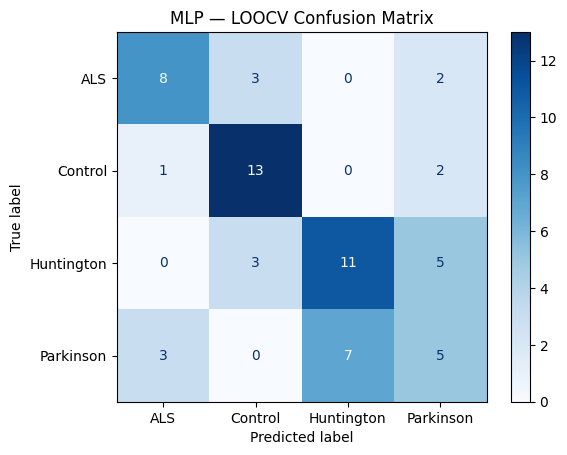

In [106]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    targets,
    predictions,
    labels=np.arange(len(encoder.classes_)),
    display_labels=encoder.classes_,
    cmap="Blues"
)

plt.title("MLP — LOOCV Confusion Matrix")
plt.show()